# Lab 4 · Un agente RAG que se autoverifica (LangGraph)

> **[ANCLA · M1]** Este lab es uno de los pilares de M1 (Corrective RAG). Hazlo entero.

**KEEPCODING · AI Engineering · Clase 5 · Módulo M1 "Agentes con LangChain"**

Cuarto lab del módulo. En los labs 1-3 el agente usaba tools; aquí le damos **conocimiento propio** con **RAG** (Retrieval-Augmented Generation) y, sobre todo, montamos un grafo de LangGraph que no solo recupera: también **se autoverifica** y decide si necesita buscar más.

## El hilo conductor

Cargamos el RAG con la transcripción **en vivo** de un episodio del podcast **spicy4tuna** (lo bajamos de YouTube al ejecutar el notebook). El grafo responderá preguntas sobre el episodio y, cuando le falte rigor, irá a **Wikipedia** (y, si tienes clave, a **Tavily**) a contrastar los hechos.

## Qué vas a aprender

- Montar un **RAG** completo: ingesta, chunking, embeddings y un vector store (**ChromaDB**).
- Diseñar un grafo de LangGraph con un **nodo verificador** que juzga si la información recopilada basta.
- Usar **salida estructurada** (`with_structured_output`) para que el veredicto del LLM dirija el grafo.
- Construir un bucle **Corrective RAG**: el grafo vuelve al RAG o salta a Wikipedia hasta tener una respuesta sólida.

## Qué necesitas

- Una clave `OPENAI_API_KEY`.
- Conexión a internet: bajamos la transcripción de YouTube, llamamos al LLM y consultamos Wikipedia.
- Corre tal cual en **Google Colab** o en **Jupyter** local.

> Recomendado haber hecho el Lab 2 (LangGraph): aquí damos por sabido `State`, nodos y aristas.

### Por qué importa

Un RAG que no se cuestiona alucina con seguridad. Añadir un nodo que juzga "¿me basta esto?" y reintenta es el salto de **RAG ingenuo a RAG fiable**, la antesala de la evaluación de RAG (clase 4 · M4).

### Conecta con

- **Slides M1** · Corrective RAG.
- **Clase 4 / M3 + M4** · RAG y su evaluación.
- **Lab 2** · damos por sabido `State`, nodos y aristas de LangGraph.
- **Lab 5** · el contraste: RAG como una tool más, no como el grafo entero.

### Stack

`langgraph>=1.0` · `langchain-chroma` · `langchain-openai` (`text-embedding-3-small`) · `youtube-transcript-api` · `gpt-5-mini`.

### Hardware

Cualquier CPU; Colab Free sobra (no usa GPU, todo es API).


## Recorrido del lab

1. **Setup**: instalar dependencias y la API key.
2. **RAG y Corrective RAG**: la idea del lab.
3. **Ingesta en vivo**: bajar la transcripción del episodio de spicy4tuna desde YouTube.
4. **Chunking**: trocear la transcripción.
5. **Indexar en ChromaDB**: embeddings y vector store.
6. **Retrieval directo**: probar la búsqueda semántica sin grafo.
7. **Wikipedia** (y Tavily, opcional): los helpers para contrastar hechos.
8. **El State** del grafo.
9. **Los nodos**: el verificador y los demás.
10. **Aristas y condicional**: cablear el grafo Corrective RAG.
11. **Visualizar** el grafo.
12. **Demo 1**: una pregunta que el podcast responde solo.
13. **Demo 2**: una pregunta que dispara varias vueltas de RAG y Wikipedia.
14. **Recap y retos**.

## 1. Setup

### 1.1. Instalar dependencias

- `langchain`, `langchain-openai`, `langgraph`: el framework, el conector de OpenAI y el motor de grafos.
- `langchain-chroma` y `chromadb`: el vector store donde vivirá el RAG.
- `youtube-transcript-api`: para bajar la transcripción del episodio.
- `tavily-python`: cliente de Tavily (opcional, solo se usa si tienes `TAVILY_API_KEY`).

> En Colab tarda unos segundos. La opción `-q` reduce el ruido.

In [1]:
%pip install -q langchain langchain-openai langgraph langchain-chroma chromadb langchain-text-splitters "youtube-transcript-api==1.2.4" tavily-python

### 1.2. Cargar la API key de OpenAI

El grafo necesita `OPENAI_API_KEY` (para los embeddings y para el LLM). Esta celda la busca en tres sitios: la variable de entorno, los secretos de Colab y, si no, la pide por teclado.

In [2]:
import os
from getpass import getpass


def cargar_api_key() -> None:
    """Asegura que OPENAI_API_KEY esté disponible en el entorno."""
    if os.environ.get("OPENAI_API_KEY"):
        print("OPENAI_API_KEY encontrada en las variables de entorno.")
        return

    # Intento 2: secretos de Google Colab.
    try:
        from google.colab import userdata

        os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
        print("OPENAI_API_KEY cargada desde los secretos de Colab.")
        return
    except Exception:
        pass

    # Intento 3: entrada manual segura.
    os.environ["OPENAI_API_KEY"] = getpass("Introduce tu OPENAI_API_KEY: ")
    print("OPENAI_API_KEY cargada desde la entrada manual.")


cargar_api_key()

OPENAI_API_KEY encontrada en las variables de entorno.


## 2. RAG y Corrective RAG

**RAG** (Retrieval-Augmented Generation) le da al LLM conocimiento que no estaba en su entrenamiento. Tres pasos:

1. **Retrieve**: buscar los fragmentos relevantes en una base de conocimiento.
2. **Augment**: meter esos fragmentos en el prompt.
3. **Generate**: el LLM responde apoyándose en ellos.

El RAG básico hace esos tres pasos **una vez** y reza. Pero, ¿y si lo recuperado no basta? ¿Y si un dato del podcast debería contrastarse con otra fuente?

**Corrective RAG** añade un paso de control: tras recuperar, un **verificador** juzga si la información es suficiente y relevante. Si no lo es, el sistema **reacciona**: vuelve a buscar con otra consulta, o salta a una fuente externa.

Eso es justo lo que construimos: un grafo de LangGraph con cuatro nodos.

| Nodo | Qué hace |
|---|---|
| `recuperar` | Busca fragmentos del podcast en ChromaDB |
| `verificar` | Un LLM juzga si lo recopilado basta para responder con rigor |
| `consultar_wikipedia` | Va a Wikipedia a contrastar o completar |
| `responder` | Redacta la respuesta final con sus fuentes |

El nodo `verificar` es el cerebro: su veredicto decide el siguiente paso. Por eso el grafo puede pasar **varias veces** por el RAG y por Wikipedia.

## 3. Ingesta en vivo: la transcripción del episodio

Cargamos el RAG con un episodio real de **spicy4tuna**, un podcast de negocio y startups. Bajamos su transcripción **en directo** desde YouTube con `youtube-transcript-api`.

Como una API pública puede fallar (YouTube a veces bloquea peticiones automáticas), incluimos un **excerpt de respaldo** incrustado: si la descarga falla, el lab sigue funcionando. Es el mismo patrón de robustez de los labs anteriores.

In [3]:
from youtube_transcript_api import YouTubeTranscriptApi

# Episodio de spicy4tuna que cargaremos en el RAG.
VIDEO_ID = "i8oXRneWPjc"

# Excerpt de respaldo: se usa solo si la descarga en vivo falla.
TRANSCRIPCION_RESPALDO = """Hoy hablaremos de la victoria de Shakira contra la Agencia Tributaria y de Zapatero y las ocupaciones de los presidentes del gobierno. También hablaremos de la primera semana con mi nueva startup y de un libro superinesante para ponerte buenos retos. También hablaremos del negocio de Brian Johnson y de cómo lo ha modificado para ganar más dinero sin vender nada. Y también comentaremos la salida bolsa de SpaceX y el cambio estructural y de tendencia que hay en el sector del Wellness. Sin más dilación, empezamos. Bienvenidos al episodio número 138 de Spice y Fortuna. Estamos como cada jueves con Euge, con Willy, con Álvaro y un servidor. Llevamos cumpliendo muchas semanas, así que, ¿qué tal, chicos? ¿Cómo estáis? Muy bien, ¿no? Oye, sin faltar. Sí, sí. Bueno, ahora en breves habrá alguna falta, ¿eh? Que ya la tenemos prevista, pero bueno. ¿Qué tal la carrera, Álvaro? Ah, muy bien. Bueno, fui a Berlín antes, eh, que esto, fue de locos y luego la carrera que fue mejor todavía. O sea, yo estoy muy contento. Has bajado tiempo, he visto, eh, he bajado 14 minutazos, que, o sea, he hecho mejor tiempo de lo que esperaba hacer en la carrera de Hux Open en Barcelona. Estoy muy contento. Bien, qué bien. ¿Tú quedado Willy? Muy bien, muy liado. He grabado muchos vídeos, no paramos. Muy contento. ¿Dónde los rabas? En Barna. Eh, depende, depende del momento, sobre todo depende del tipo de grabación. Puede ser en Barcelona, puede ser aquí en Andorra, puede ser en Madrid, pero sueles poner varias grabaciones, ¿no? A la vez. Sí. O incluso, por ejemplo, ahora estoy grabando, yo que sé, como yo me lo paso bien grabando, pues me viene alguien me dice, "Oye, ¿te parece venirte a grabar un vídeo?" Seí. Digo, "Vale, pero por lo menos juntados." Ojo, bien el de las parejas. El de las parejas. Yo también. Si hubieses visto el padrino, ¿no te habría pasado el el fail en la en la pregunta de las? Bueno, no acertasteis, ¿no? La última película que habíais visto. Ah, bueno, claro, si hubies, ¿te acordarías? Si hubieses visto tres horas de padrino, te acordarías. Hombre, yo creo que a mi mujer no la pongo tres horas a ver al el padrino. No aguanto ni yo. Es imposible. Muy mal, muy mal. Yo pues currando como un cabrón y justo ahora vengo de de hacer una acción con el Andorra de fútbol que está chutando penaltis al portero profesional y os sorprenderá el resultado, os lo pondré en la newsletter, vais a flipar. O sea, yo iba para futbolista, pero me perdió me perdieron otras cosas. Oye, hablando de perder, eh, hay gente que pierde la salud, pierde el dinero, pierde pues el foco cuando pues de repente aparece Hacienda por la puerta, te pica te pica la puerta, ¿no? Y te abre una inspección. Vale. Eh, creo creo que Willy puede puede compartir su experiencia, pero estamos luchando."""


def descargar_transcripcion(video_id: str) -> str:
    """Baja la transcripción en español de un video de YouTube y la une en un texto."""
    api = YouTubeTranscriptApi()
    fragmentos = api.fetch(video_id, languages=["es"])
    return " ".join(fragmento.text for fragmento in fragmentos)


try:
    transcripcion = descargar_transcripcion(VIDEO_ID)
    print(f"Transcripción descargada en vivo desde YouTube: {len(transcripcion):,} caracteres.")
except Exception as error:
    print(f"No se pudo descargar de YouTube ({type(error).__name__}). Uso el excerpt de respaldo.")
    transcripcion = TRANSCRIPCION_RESPALDO
    print(f"Excerpt de respaldo: {len(transcripcion):,} caracteres.")

print("\nPrimeros 300 caracteres:\n")
print(transcripcion[:300], "...")

Transcripción descargada en vivo desde YouTube: 119,063 caracteres.

Primeros 300 caracteres:

Hoy hablaremos de la victoria de Shakira contra la Agencia Tributaria y de Zapatero y las ocupaciones de los presidentes del gobierno. También hablaremos de la primera semana con mi nueva startup y de un libro superinesante para ponerte buenos retos. También hablaremos del negocio de Brian Johnson y ...


## 4. Chunking: trocear la transcripción

Un LLM no puede (ni debe) tragarse toda la transcripción de golpe. La partimos en **chunks**: trozos pequeños que se puedan recuperar de forma independiente.

`RecursiveCharacterTextSplitter` corta intentando respetar párrafos y frases. Dos parámetros:

- `chunk_size`: tamaño objetivo de cada trozo, en caracteres.
- `chunk_overlap`: solape entre trozos consecutivos, para no cortar una idea por la mitad.

In [4]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

divisor = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150)
trozos = divisor.split_text(transcripcion)

print(f"La transcripción se partió en {len(trozos)} chunks.")
indice_ejemplo = 5 if len(trozos) > 5 else 0
print(f"\nEjemplo (chunk {indice_ejemplo} de {len(trozos)}):\n")
print(trozos[indice_ejemplo])

La transcripción se partió en 159 chunks.

Ejemplo (chunk 5 de 159):

era la cantidad que le habían eh confiscado eh claramente eh por considerarla como residente fiscal en este de 2011. Estamos en 2026, ¿correcto? O sea, hay como 20 millones. ¿Cuánto hay de intereses que tienen que pagar ahora todos los ciudadanos? No, no son 9 millones de intereses según han calculado, pero es que encima la Audiencia Nacional ha condenado a la Agencia Tributaria en costas, que es algo que es muy poco habitual. Esto puede pasarme a mí. Puede pasar, pero es muy poco habitual. Es muy poco habitual. ocurrir. Ha sido ha sido algo eh excepcional y como un toque de atención, decir, chicos, no podéis ir a saco porque entonces al contribuyente le obligas a ir hasta el final a gastarse cientos de miles de euros en abogados y claro, tiene sentido que si por una temeridad o por una o por una locura de un inspector me haces gastarme esa pasta, el juez determine que las costas las


## 5. Indexar en ChromaDB

Ahora convertimos cada chunk en un **embedding** (un vector que captura su significado) y lo guardamos en **ChromaDB**, un vector store que corre dentro del propio notebook, sin servidor.

- `OpenAIEmbeddings` con `text-embedding-3-small`: barato y bueno para clase.
- Cada chunk se envuelve en un `Document` con metadatos (su número de chunk), útil para citar la fuente.
- `Chroma.from_documents` calcula los embeddings y los indexa de una vez.

In [5]:
from langchain_core.documents import Document
from langchain_openai import OpenAIEmbeddings
from langchain_chroma import Chroma

# Cada chunk pasa a ser un Document con su metadato de origen.
documentos = [
    Document(page_content=trozo, metadata={"fuente": "podcast spicy4tuna", "chunk": i})
    for i, trozo in enumerate(trozos)
]

# El modelo de embeddings: convierte texto en vectores.
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

# ChromaDB indexa los documentos. Corre en memoria, dentro del notebook.
vector_store = Chroma.from_documents(
    documents=documentos,
    embedding=embeddings,
    collection_name="spicy4tuna",
)

# Un retriever es la interfaz de búsqueda: dada una query, devuelve los k más parecidos.
retriever = vector_store.as_retriever(search_kwargs={"k": 4})

print(f"Indexados {len(documentos)} chunks en ChromaDB. Retriever listo (k=4).")

Indexados 159 chunks en ChromaDB. Retriever listo (k=4).


## 6. Probar el retrieval directo

Antes de montar el grafo, comprobemos que la búsqueda semántica funciona. El retriever recibe una pregunta en lenguaje natural y devuelve los chunks más **parecidos en significado**, no por coincidencia de palabras.

In [6]:
consulta_prueba = "que cuentan sobre Shakira y Hacienda"
resultados = retriever.invoke(consulta_prueba)

print(f"Consulta: {consulta_prueba!r}")
print(f"Chunks recuperados: {len(resultados)}\n")
for doc in resultados:
    print(f"--- Chunk {doc.metadata['chunk']} ---")
    print(doc.page_content[:200], "...\n")

Consulta: 'que cuentan sobre Shakira y Hacienda'
Chunks recuperados: 4

--- Chunk 16 ---
de inversión antes de la crisis de 2008, ¿sabes? Que cobraban unos bonus de la [ __ ] y luego todo se estampa y claro. Entonces aquí el punto es que que Hacienda, evidentemente, pues tiene sus herrami ...

--- Chunk 6 ---
tiene sentido que si por una temeridad o por una o por una locura de un inspector me haces gastarme esa pasta, el juez determine que las costas las paga la administración. Ha sido tan claro que el tri ...

--- Chunk 13 ---
del tiempo y eso está claro, pero es que en este caso ni así han han conseguido probar más de 150 días. En consecuencia, eh la Audiencia Nacional ha fallado en contra de Hacienda, condenándolos tambié ...

--- Chunk 4 ---
contestación de Audiencia Nacional. Nada, está Yo lo veo, lo veo bien. No se puede decir nunca que se ha ganado, pero lo veo bien, ¿eh? Pero yo creo que añuel pasta, año y medio, dos años. Qué barbari ...



## 7. La fuente de contraste: Wikipedia

El podcast cuenta cosas, pero un buen sistema **contrasta**. Damos al grafo un helper para consultar **Wikipedia en español**.

Wikipedia necesita el título casi exacto de un artículo. Por eso el helper hace **dos pasos**:

1. `opensearch`: resuelve el título de artículo más cercano a la consulta.
2. `summary`: trae el resumen de ese artículo.

Si algo falla, devuelve un mensaje útil en vez de romper: una función robusta nunca lanza la excepción hacia el grafo.

In [7]:
import urllib.request
import urllib.parse
import json

_WIKI_UA = {"User-Agent": "keepcoding-ai-lab/1.0 (curso KEEPCODING)"}


def buscar_wikipedia(consulta: str) -> str:
    """Devuelve el resumen del artículo de Wikipedia en español más cercano a la consulta.

    Resuelve primero el título con la API opensearch y luego pide el resumen.
    Devuelve un mensaje claro si no hay resultados o si la consulta falla.
    """
    try:
        # Paso 1: resolver el título de artículo más parecido.
        params = urllib.parse.urlencode(
            {"action": "opensearch", "search": consulta, "limit": 1, "format": "json"}
        )
        url_buscar = f"https://es.wikipedia.org/w/api.php?{params}"
        req = urllib.request.Request(url_buscar, headers=_WIKI_UA)
        with urllib.request.urlopen(req, timeout=15) as r:
            datos = json.load(r)
        titulos = datos[1]
        if not titulos:
            return f"Wikipedia no tiene un artículo para '{consulta}'."

        # Paso 2: traer el resumen de ese artículo.
        titulo = titulos[0]
        slug = urllib.parse.quote(titulo.replace(" ", "_"))
        url_resumen = f"https://es.wikipedia.org/api/rest_v1/page/summary/{slug}"
        req2 = urllib.request.Request(url_resumen, headers=_WIKI_UA)
        with urllib.request.urlopen(req2, timeout=15) as r:
            resumen = json.load(r)
        extracto = resumen.get("extract") or "(artículo sin resumen)"
        return f"[Wikipedia: {titulo}] {extracto}"
    except Exception as error:
        return f"No se pudo consultar Wikipedia para '{consulta}': {error}"


# Prueba rápida del helper
print(buscar_wikipedia("Shakira"))

[Wikipedia: Shakira] Shakira Isabel Mebarak Ripoll, conocida simplemente como Shakira, es una cantante, compositora, productora, bailarina, multinstrumentista, empresaria y actriz colombiana. Apodada como la «Reina del pop latino», es considerada un icono de la música latina por su alto nivel de ventas, versatilidad vocal, éxito e influencia global.Desde su debut en los años 90 hasta la actualidad ha tenido una gran repercusión en la escena musical, siendo citada en numerosas ocasiones por inspirar e influir a toda una generación de cantantes. Con una carrera artística de más de treinta años,es ampliamente reconocida como la «artista latina más exitosa e influyente de todos los tiempos».Del mismo modo, es la artista latina con mayores ventas discográficas en la historia, con más de 125 millones de álbumes y sencillos vendidos.


### 7.1. Fuente opcional: Tavily (búsqueda web para agentes)

Además de Wikipedia, el grafo puede contrastar datos en internet con **Tavily**, un buscador pensado para agentes. Necesita una clave `TAVILY_API_KEY` (tiene plan gratuito en [tavily.com](https://tavily.com)).

Es **opcional**: si no tienes clave, la celda lo detecta, avisa y el grafo sigue funcionando solo con el podcast y Wikipedia. Nunca pegues la clave en el código: léela del entorno o de los Secrets de Colab.

In [8]:
import os

# Tavily es OPCIONAL. Buscamos la clave en el entorno y, en Colab, en los Secrets.
TAVILY_API_KEY = os.environ.get("TAVILY_API_KEY")
if not TAVILY_API_KEY:
    try:
        from google.colab import userdata

        TAVILY_API_KEY = userdata.get("TAVILY_API_KEY")
    except Exception:
        TAVILY_API_KEY = None

TAVILY_DISPONIBLE = bool(TAVILY_API_KEY)


def buscar_tavily(consulta: str) -> str:
    """Busca en la web con Tavily y devuelve los resultados resumidos con su URL.

    Si no hay TAVILY_API_KEY o la llamada falla, devuelve un mensaje claro
    en vez de romper el grafo.
    """
    if not TAVILY_DISPONIBLE:
        return "Tavily no disponible (falta TAVILY_API_KEY): solo se usan el podcast y Wikipedia."
    try:
        from tavily import TavilyClient

        cliente = TavilyClient(api_key=TAVILY_API_KEY)
        respuesta = cliente.search(query=consulta, search_depth="advanced", max_results=4)
        lineas = [
            f"- {r.get('title', '')}: {(r.get('content') or '')[:300]} ({r.get('url', '')})"
            for r in respuesta.get("results", [])
        ]
        return "[Tavily]\n" + ("\n".join(lineas) or f"Sin resultados para '{consulta}'.")
    except Exception as error:
        return f"No se pudo consultar Tavily para '{consulta}': {error}"


if TAVILY_DISPONIBLE:
    print("Tavily disponible: el verificador podrá usarlo para contrastar datos en internet.")
else:
    print("Aviso: no hay TAVILY_API_KEY. El nodo de Tavily queda desactivado y "
          "el grafo usará solo el podcast y Wikipedia.")

Aviso: no hay TAVILY_API_KEY. El nodo de Tavily queda desactivado y el grafo usará solo el podcast y Wikipedia.


## 8. El State del grafo

El `State` es la estructura que viaja entre nodos. Cada nodo lo lee y devuelve una actualización.

Nuestro grafo necesita recordar bastante:

| Campo | Qué guarda |
|---|---|
| `pregunta` | La pregunta original del usuario |
| `consulta` | La query actual de búsqueda (el verificador la va afinando) |
| `docs_podcast` | Los chunks del podcast recuperados hasta ahora |
| `notas_wikipedia` | Lo encontrado en Wikipedia hasta ahora |
| `webs_tavily` | Lo encontrado en Tavily hasta ahora (opcional) |
| `veredicto` | El último dictamen del nodo verificador |
| `vueltas` | Contador de verificaciones (tope anti-bucle) |
| `respuesta` | La respuesta final |

`docs_podcast`, `notas_wikipedia` y `webs_tavily` se van **acumulando**: cada nodo lee lo que hay y devuelve la lista ampliada.

In [9]:
from typing_extensions import TypedDict


class Estado(TypedDict):
    """Todo lo que el grafo Corrective RAG necesita recordar entre nodos."""
    pregunta: str
    consulta: str
    docs_podcast: list[str]
    notas_wikipedia: list[str]
    webs_tavily: list[str]
    veredicto: dict
    vueltas: int
    respuesta: str


print("Estado del grafo definido.")

Estado del grafo definido.


## 9. Los nodos del grafo

### El nodo estrella: `verificar`

Aquí está lo interesante del grafo. El nodo `verificar` es un LLM que actúa de **juez**: mira la pregunta y todo lo recopilado (podcast + Wikipedia + Tavily) y decide si basta.

Para que su decisión pueda **dirigir el grafo**, no queremos texto libre: queremos una respuesta **estructurada**. `with_structured_output` obliga al LLM a rellenar un modelo `Veredicto` con campos tipados:

- `suficiente`: booleano, si lo recopilado basta para responder con rigor.
- `razon`: por qué.
- `siguiente`: a dónde ir (`podcast`, `wikipedia`, `tavily` o `responder`).
- `consulta_sugerida`: la query afinada para la siguiente búsqueda.

Ese objeto tipado es lo que la arista condicional leerá para enrutar.

In [10]:
from typing import Literal
from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI


class Veredicto(BaseModel):
    """Dictamen estructurado del nodo verificador."""
    suficiente: bool = Field(
        description="True si lo recopilado basta para responder la pregunta con rigor."
    )
    razon: str = Field(description="Explicación breve de qué falta o por qué basta.")
    siguiente: Literal["podcast", "wikipedia", "tavily", "responder"] = Field(
        description="Próximo paso: buscar más en el podcast, ir a Wikipedia, ir a buscar a Tavily, o responder ya."
    )
    consulta_sugerida: str = Field(
        description=(
            "Query afinada para la siguiente búsqueda. Si siguiente='wikipedia', "
            "debe ser el NOMBRE de una entidad tal cual la titularía Wikipedia "
            "(por ejemplo 'Shakira' o 'Bryan Johnson'), no una frase. Vacío si se responde ya."
        )
    )


# El modelo de chat para todo el grafo.
llm = ChatOpenAI(model="gpt-5-mini")

# Un LLM que SIEMPRE devuelve un objeto Veredicto, no texto libre.
verificador = llm.with_structured_output(Veredicto)

print("Modelo y verificador con salida estructurada listos.")

Modelo y verificador con salida estructurada listos.


### Los otros nodos

- `recuperar`: busca en ChromaDB con la consulta actual y acumula los chunks nuevos.
- `consultar_wikipedia`: pide a Wikipedia la entidad sugerida por el verificador.
- `consultar_tavily`: busca en internet con Tavily (solo si hay `TAVILY_API_KEY`).
- `responder`: redacta la respuesta final, distinguiendo lo que dice el podcast de lo contrastado en Wikipedia o Tavily.

Cada nodo recibe el `Estado` y devuelve solo los campos que cambia.

In [11]:
# --- Nodo 1: recuperar (busca en el RAG del podcast) ---
def recuperar(estado: Estado) -> dict:
    """Recupera chunks del podcast para la consulta actual y los acumula sin duplicar."""
    consulta = estado["consulta"] or estado["pregunta"]
    encontrados = retriever.invoke(consulta)
    nuevos = [d.page_content for d in encontrados]
    acumulados = estado["docs_podcast"] + [
        d for d in nuevos if d not in estado["docs_podcast"]
    ]
    ganados = len(acumulados) - len(estado["docs_podcast"])
    print(f"  [recuperar] consulta={consulta!r} -> +{ganados} chunks nuevos")
    return {"docs_podcast": acumulados}


# --- Nodo 2: verificar (juzga si lo recopilado basta) ---
def verificar(estado: Estado) -> dict:
    """El LLM juez: decide si hay info suficiente y, si no, a dónde ir a buscar."""
    vueltas = estado["vueltas"] + 1
    contexto = "\n\n".join(estado["docs_podcast"]) or "(todavía sin chunks del podcast)"
    wikipedia = "\n\n".join(estado["notas_wikipedia"]) or "(todavía sin notas de Wikipedia)"
    tavily = "\n\n".join(estado["webs_tavily"]) or "(todavía sin notas de Tavily)"
    # Títulos ya consultados en Wikipedia: así el verificador no repite la misma búsqueda.
    consultadas = ", ".join(
        n.split("]")[0].replace("[Wikipedia: ", "") for n in estado["notas_wikipedia"] if n.startswith("[Wikipedia:")
    )

    prompt = (
        "Eres un verificador riguroso de un sistema RAG. Decide si la información "
        "recopilada basta para responder la pregunta con rigor y con datos contrastados.\n\n"
        f"PREGUNTA:\n{estado['pregunta']}\n\n"
        f"CONTEXTO DEL PODCAST:\n{contexto}\n\n"
        f"NOTAS DE WIKIPEDIA:\n{wikipedia}\n\n"
        f"WEBS DE TAVILY:\n{tavily}\n\n"
        f"YA CONSULTADO EN WIKIPEDIA: {consultadas or '(nada)'}\n\n"
        "Criterios:\n"
        "- Si el contexto del podcast no cubre la pregunta, elige 'podcast' con otra consulta.\n"
        "- Si la pregunta menciona personas o hechos que conviene contrastar y aún no están en las "
        "NOTAS DE WIKIPEDIA, elige 'wikipedia' con una entidad nueva (no repitas una ya consultada).\n"
        + (
            "- Si necesitas contrastar datos actuales en internet, elige 'tavily'.\n"
            if TAVILY_DISPONIBLE
            else "- La opción 'tavily' NO está disponible: no la elijas.\n"
        )
        + "- Si ya hay material suficiente y contrastado, elige 'responder'.\n"
        "- Si las fuentes disponibles ya no aportan nada nuevo, elige 'responder' "
        "y deja claro qué no se ha podido contrastar."
    )
    dictamen = verificador.invoke(prompt)
    print(f"  [verificar] vuelta {vueltas}: suficiente={dictamen.suficiente} "
          f"-> siguiente={dictamen.siguiente} ({dictamen.razon})")
    return {
        "veredicto": dictamen.model_dump(),
        "vueltas": vueltas,
        "consulta": dictamen.consulta_sugerida,
    }


print("Nodos 'recuperar' y 'verificar' definidos.")

Nodos 'recuperar' y 'verificar' definidos.


In [12]:
# --- Nodo 3: consultar_wikipedia (contrasta con una fuente externa) ---
def consultar_wikipedia(estado: Estado) -> dict:
    """Consulta Wikipedia con la entidad sugerida por el verificador."""
    consulta = estado["consulta"] or estado["pregunta"]
    resumen = buscar_wikipedia(consulta)
    print(f"  [consultar_wikipedia] {consulta!r}")
    if resumen in estado["notas_wikipedia"]:
        # Ya teníamos esta nota: no la duplicamos.
        return {"notas_wikipedia": estado["notas_wikipedia"]}
    return {"notas_wikipedia": estado["notas_wikipedia"] + [resumen]}

def consultar_tavily(estado: Estado) -> dict:
    """Consulta Tavily con la entidad sugerida por el verificador."""
    consulta = estado["consulta"] or estado["pregunta"]
    resumen = buscar_tavily(consulta)
    print(f"  [consultar_tavily] {consulta!r}")
    return {"webs_tavily": estado["webs_tavily"] + [resumen]}


# --- Nodo 4: responder (redacta la respuesta final) ---
def responder(estado: Estado) -> dict:
    """Redacta la respuesta final distinguiendo el podcast de Wikipedia."""
    contexto = "\n\n".join(estado["docs_podcast"]) or "(sin contexto del podcast)"
    wikipedia = "\n\n".join(estado["notas_wikipedia"]) or "(sin notas de Wikipedia)"
    tavily = "\n\n".join(estado["webs_tavily"]) or "(sin notas de Tavily)"

    prompt = (
        "Responde a la pregunta usando ÚNICAMENTE la información proporcionada. "
        "Distingue con claridad lo que dice el podcast de lo que aportan Wikipedia y Tavily. "
        "Si algo no está en las fuentes, dilo. Responde en español, claro y conciso, "
        "y cierra citando las fuentes usadas.\n\n"
        f"PREGUNTA:\n{estado['pregunta']}\n\n"
        f"CONTEXTO DEL PODCAST (spicy4tuna):\n{contexto}\n\n"
        f"NOTAS DE WIKIPEDIA:\n{wikipedia}\n\n"
        f"WEBS DE TAVILY:\n{tavily}"
    )
    salida = llm.invoke(prompt)
    return {"respuesta": salida.content}


print("Nodos 'consultar_wikipedia', 'consultar_tavily' y 'responder' definidos.")

Nodos 'consultar_wikipedia', 'consultar_tavily' y 'responder' definidos.


## 10. Las aristas: cablear el grafo Corrective RAG

Los nodos ya existen; falta el cableado. La pieza clave es la **arista condicional** tras `verificar`: una función `enrutar` lee el veredicto y devuelve el nombre del siguiente nodo.

- `START -> recuperar -> verificar`: siempre empezamos buscando y verificando.
- Desde `verificar`, la condicional:
  - `podcast` -> vuelve a `recuperar` (otra búsqueda en el RAG).
  - `wikipedia` -> va a `consultar_wikipedia`.
  - `tavily` -> va a `consultar_tavily` (si no hay clave, se redirige a Wikipedia).
  - `responder` -> salta a `responder`.
- `consultar_wikipedia -> verificar` y `consultar_tavily -> verificar`: tras cada fuente externa, **se vuelve a verificar** con la info nueva.
- `responder -> END`.

El contador `vueltas` es el cinturón de seguridad: pasadas unas cuantas verificaciones forzamos `responder` aunque el veredicto no esté satisfecho. Un grafo con ciclos nunca debe poder buclear infinito.

In [13]:
from langgraph.graph import StateGraph, START, END

# Tope de verificaciones: agota el bucle aunque el veredicto no quede satisfecho.
MAX_VUELTAS = 4


def enrutar(estado: Estado) -> str:
    """Lee el veredicto y decide el siguiente nodo tras 'verificar'."""
    if estado["vueltas"] >= MAX_VUELTAS:
        return "responder"
    veredicto = estado["veredicto"]
    if veredicto.get("suficiente") or veredicto.get("siguiente") == "responder":
        return "responder"
    if veredicto.get("siguiente") == "wikipedia":
        return "consultar_wikipedia"
    if veredicto.get("siguiente") == "tavily":
        # Sin clave de Tavily, contrastamos en Wikipedia en su lugar.
        return "consultar_tavily" if TAVILY_DISPONIBLE else "consultar_wikipedia"
    return "recuperar"


# Construimos el grafo.
constructor = StateGraph(Estado)
constructor.add_node("recuperar", recuperar)
constructor.add_node("verificar", verificar)
constructor.add_node("consultar_wikipedia", consultar_wikipedia)
constructor.add_node("consultar_tavily", consultar_tavily)
constructor.add_node("responder", responder)

constructor.add_edge(START, "recuperar")
constructor.add_edge("recuperar", "verificar")
constructor.add_conditional_edges(
    "verificar",
    enrutar,
    {
        "recuperar": "recuperar",
        "consultar_wikipedia": "consultar_wikipedia",
        "consultar_tavily": "consultar_tavily",
        "responder": "responder",
    },
)
constructor.add_edge("consultar_wikipedia", "verificar")
constructor.add_edge("consultar_tavily", "verificar")
constructor.add_edge("responder", END)

grafo = constructor.compile()
print("Grafo Corrective RAG compilado.")

Grafo Corrective RAG compilado.


## 11. Visualizar el grafo

Como en el Lab 2, dibujamos el grafo. Fíjate en el **ciclo**: `verificar` puede volver a `recuperar` o ir a `consultar_wikipedia` / `consultar_tavily`, y ambas regresan a `verificar`. Ese bucle es lo que convierte un RAG normal en un Corrective RAG.

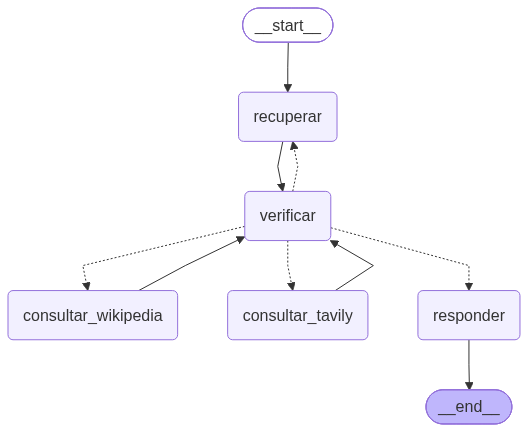

In [14]:
from IPython.display import Image, display

try:
    display(Image(grafo.get_graph().draw_mermaid_png()))
except Exception as error:
    print(f"No se pudo renderizar el PNG ({type(error).__name__}). Diagrama en texto:\n")
    print(grafo.get_graph().draw_ascii())

## 12. Demo 1: una pregunta que el podcast responde solo

Empezamos con una pregunta cuya respuesta está **dentro del episodio**. Esperamos un camino corto: `recuperar -> verificar -> responder`, sin pasar por Wikipedia.

La función `preguntar` ejecuta el grafo con `stream` para ver cada nodo según se ejecuta. Los nodos van imprimiendo su propio rastro.

In [15]:
def preguntar(pregunta: str) -> str:
    """Ejecuta el grafo Corrective RAG y muestra el recorrido nodo a nodo."""
    estado_inicial = {
        "pregunta": pregunta,
        "consulta": pregunta,
        "docs_podcast": [],
        "notas_wikipedia": [],
        "webs_tavily": [],
        "veredicto": {},
        "vueltas": 0,
        "respuesta": "",
    }
    print(f"PREGUNTA: {pregunta}\n")
    print("Recorrido del grafo:")
    respuesta = ""
    for paso in grafo.stream(estado_inicial, stream_mode="updates"):
        for _nodo, actualizacion in paso.items():
            if "respuesta" in actualizacion:
                respuesta = actualizacion["respuesta"]
    print("\n" + "=" * 60)
    print("RESPUESTA FINAL:")
    print("=" * 60)
    print(respuesta)
    return respuesta


_ = preguntar("¿Qué cuenta el host sobre la primera semana con su nueva startup?")

PREGUNTA: ¿Qué cuenta el host sobre la primera semana con su nueva startup?

Recorrido del grafo:


  [recuperar] consulta='¿Qué cuenta el host sobre la primera semana con su nueva startup?' -> +4 chunks nuevos


  [verificar] vuelta 1: suficiente=True -> siguiente=responder (El fragmento del podcast describe de forma directa y repetida la primera semana: anuncio del lanzamiento, aumento enorme de intensidad (x10), ~150 peticiones de prueba, trabajo simultáneo en producto y en gestión de usuarios (llamadas), cambio de autoservicio a onboarding manual en 3 horas, sensación de product–market fit muy fuerte, jornada extensa (7:00–00:00) y entusiasmo renovado. Esa información basta para responder con rigor lo que contó el host.)



RESPUESTA FINAL:
Lo que cuenta el host (según el podcast):
- Anunció el lanzamiento de su nueva startup la semana pasada y la primera semana multiplicó su intensidad de trabajo por 10.
- Recibió aproximadamente 150 peticiones de gente que quiere probar el servicio.
- Está simultaneando programar el producto y gestionar a esas personas: entrar en llamadas, hablar con ellos y acompañarles.
- Pensó al principio que el producto sería autoservicio, pero cambió esa idea a las 3 horas porque detectó que es un software complejo y necesita atención directa (se compara con ser “mamá helicóptero”).
- Los usuarios prueban cosas que él no había imaginado, por lo que el proceso es más demandante de lo que esperaba.
- Está trabajando muchas horas (dice que desde las 7 de la mañana hasta las 12 de la noche).
- Está muy ilusionado: siente de nuevo la energía de la fase inicial de una startup y percibe un market-fit muy fuerte; las demos “encajan” rápido y convierte con mucha facilidad (“no he vendido 

## 13. Demo 2: una pregunta que dispara la autoverificación

Ahora una pregunta que el podcast menciona pero que **conviene contrastar** con hechos externos. El verificador debería detectar que faltan datos factuales y mandar el grafo a Wikipedia, quizá **varias veces**, y también pedir más contexto del podcast.

Observa el recorrido: verás `verificar` repetirse y alternar entre `recuperar` y `consultar_wikipedia` antes de `responder`. El camino exacto lo decide el LLM en cada ejecución.

In [16]:
_ = preguntar(
    "En el episodio hablan de la victoria de Shakira contra la Agencia Tributaria. "
    "Resume qué dicen, contrasta quién es Shakira y en qué consistió el caso fiscal, "
    "y contrasta los datos con fuentes externas."
)

PREGUNTA: En el episodio hablan de la victoria de Shakira contra la Agencia Tributaria. Resume qué dicen, contrasta quién es Shakira y en qué consistió el caso fiscal, y contrasta los datos con fuentes externas.

Recorrido del grafo:


  [recuperar] consulta='En el episodio hablan de la victoria de Shakira contra la Agencia Tributaria. Resume qué dicen, contrasta quién es Shakira y en qué consistió el caso fiscal, y contrasta los datos con fuentes externas.' -> +4 chunks nuevos


  [verificar] vuelta 1: suficiente=False -> siguiente=wikipedia (El extracto del podcast da una narrativa general (dice que Shakira perdió por los ejercicios 2012‑2014 y que ganó sobre 2011 con una devolución ~60M€) pero no aporta datos verificables ni fechas claras: faltan la cronología judicial precisa, las cifras oficiales, la naturaleza exacta de las resoluciones (condena penal, acuerdo/fianza, absolución parcial), y la confirmación de la decisión de la Audiencia Nacional y del importe devuelto. Para responder con rigor hay que contrastar con fuentes externas (p. ej. entrada de Wikipedia y sentencias/medios fiables).)


  [consultar_wikipedia] 'Shakira'


  [verificar] vuelta 2: suficiente=False -> siguiente=wikipedia (El extracto del podcast contiene afirmaciones concretas (años en que supuestamente perdió: 2012-2014; condena por delito fiscal y pacto con la fiscalía; victoria en 2011 reconocida por la Audiencia Nacional con devolución de ~60 millones). Para responder con rigor hay que contrastar esas fechas, las resoluciones judiciales concretas (qué tribunal falló qué años), la existencia y términos de cualquier pacto o condena penal, y la cifra exacta devuelta/retirada por Hacienda. Esos detalles no están en las notas de Wikipedia ya entregadas.)


  [consultar_wikipedia] 'Shakira'


  [verificar] vuelta 3: suficiente=False -> siguiente=wikipedia (El extracto del podcast ofrece afirmaciones concretas pero parciales (qué años ganó/perdió, si hubo condena penal o pacto, y la cifra de ~60 millones devueltos). Las NOTAS DE WIKIPEDIA sobre Shakira sólo aportan su biografía general y no confirman los detalles judiciales ni las resoluciones de la Audiencia Nacional ni las cifras reclamadas. Hace falta comprobar la sentencia/resolución concreta, la calificación penal o el acuerdo con la Fiscalía y las cantidades efectivamente devueltas o reclamadas en fuentes externas fiables.)


  [consultar_wikipedia] 'Audiencia Nacional'


  [verificar] vuelta 4: suficiente=False -> siguiente=wikipedia (El extracto del podcast da afirmaciones concretas (qué años perdió, que pactó con Fiscalía, que ganó el caso de residencia de 2011 y le devolvieron 60 millones, cifras aproximadas) pero no aporta fuentes ni documentos. Las notas de Wikipedia incluidas solo describen a Shakira y la Audiencia Nacional de forma general; faltan referencias a la sentencia, al pronunciamiento de la Audiencia Nacional, a la posición de la Agencia Tributaria y a medios fiables que confirmen montos y años exactos. Para contrastar rigurosamente hace falta consultar fuentes externas (Agencia Tributaria, la resolución judicial y medios de referencia).)



RESPUESTA FINAL:
Resumen de lo que dice el podcast (spicy4tuna)
- El presentador explica que, leyendo la sentencia, concluye que Shakira "ha perdido" frente a la Agencia Tributaria en los ejercicios 2012, 2013 y 2014: fue condenada por delito fiscal, imputada penalmente y llegó a un pacto con la Fiscalía reconociendo que infringió la ley española.  
- Añade que hay otra resolución: la Audiencia Nacional le habría dado la razón a Shakira respecto a su residencia fiscal en 2011, por lo que la Agencia Tributaria le devolvería unos 60 millones de euros que le habían retenido por considerarla residente en España en 2011.  
- Concluye que, por tanto, Shakira habría perdido varios años (12–14) pero ganado el de 2011; menciona además cantidades orientativas para otros años (14–15 millones por año) y que en 2011 fue un año "gordo" de ingresos.  
- Comenta también que Shakira habría hecho un comunicado sobre el "escarnio público", y que la resolución ha generado reels y explicaciones superficia

## 14. Recap y retos

### Lo que has construido

Un **agente RAG con autoverificación**, como grafo de LangGraph:

| Pieza | Qué aporta |
|---|---|
| Ingesta en vivo | La transcripción real de un episodio, bajada de YouTube |
| ChromaDB | El vector store que guarda y busca el conocimiento |
| Nodo `verificar` | El juez con salida estructurada que dirige el grafo |
| Bucle Corrective RAG | El grafo vuelve al RAG o salta a Wikipedia (o Tavily) hasta tener rigor |
| Nodo `responder` | Una respuesta que separa el podcast de la fuente externa |

### Ideas clave

- Un RAG básico recupera una vez; un **Corrective RAG se autoevalúa** y reacciona.
- `with_structured_output` convierte al LLM en una pieza **fiable de control de flujo**: su veredicto tipado dirige las aristas.
- Verificar contra una **segunda fuente** (Wikipedia) sube la calidad y reduce alucinaciones.
- El contador `vueltas` evita bucles infinitos: todo grafo con ciclos necesita un tope.

### Retos para practicar

1. **Verificar la respuesta final**: añade un quinto nodo que compruebe si la `respuesta` está **fundamentada** en las fuentes; si detecta una afirmación sin respaldo, que vuelva a `recuperar`.
2. **Más fuentes**: añade un nodo que consulte otra API y deja que el verificador elija entre tres fuentes.
3. **Memoria**: compila el grafo con un `checkpointer` (Lab 2) y un `thread_id` para hacer preguntas de seguimiento.
4. **Persistir el índice**: pasa a `Chroma` un `persist_directory` para no reindexar la transcripción en cada ejecución.
5. **Otro episodio**: cambia `VIDEO_ID` por otro video de spicy4tuna y observa cómo cambian las respuestas.

> Con esto cierras el bloque de grafos del M1: del agente que razona (Lab 1), al grafo explícito (Lab 2), al protocolo de tools (Lab 3) y al RAG que se autoverifica (Lab 4). En el Lab 5 verás el contraste: RAG como una tool más dentro de un agente.